# 04 · Anomalies and association rules

**Question:** How does CrimeScope identify unusual cross-sectional counts and category co-presence in district reporting profiles?

**Input and scope:** Verified 2024 active feature input and the saved anomaly/rule artifacts from the run selected by `analysis/output/runs/current.json`. A transaction is one eligible administrative district’s 2024 category profile. No event-level records are available here.

In [1]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "analysis/output/runs/current.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("CrimeScope root not found; open from the repo root or notebooks folder. See docs/handoff.md.")
sys.path.insert(0, str(ROOT / "analysis/src"))

def read_json(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Required artifact missing: {path}. Restore the analysis handoff described in docs/handoff.md.")
    return json.loads(path.read_text(encoding="utf-8"))

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

release_pointer = read_json(ROOT / "data/serving/current.json")
release = read_json(ROOT / release_pointer["release_path"] / "release_manifest.json")
run_pointer = read_json(ROOT / "analysis/output/runs/current.json")
run_manifest_path = ROOT / run_pointer["manifest"]
run = read_json(run_manifest_path)
run_dir = run_manifest_path.parent
feature_path = ROOT / run["feature_input"]["path"]
for path, expected, label in [(feature_path, run["feature_input"]["sha256"], "active feature input")]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing {label}: {path}. Restore the local analysis handoff described in docs/handoff.md.")
    assert sha256(path) == expected, f"{label} hash mismatch at {path}; restore the manifest-selected artifact."
assert run_pointer["run_id"] == run["run_id"]

def artifact(relative):
    path = run_dir / relative
    expected = run["artifacts"].get(relative)
    if expected is None:
        raise KeyError(f"Active run manifest does not list expected artifact {relative}")
    if not path.is_file():
        raise FileNotFoundError(f"Active run artifact missing: {path}. Restore the active analysis handoff described in docs/handoff.md.")
    assert sha256(path) == expected, f"Saved artifact hash mismatch: {path}"
    return path

print(f"Run: {run['run_id']} | cohort: {run['feature_input']['regions']} eligible administrative districts × {run['feature_input']['features']} categories")

# --- CrimeScope notebook figure style ---
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PRIMARY = "#237866"
ACCENT = "#d47a43"
BLUE = "#3d7894"
RED = "#b91c1c"
GREY = "#94a3b8"
SERIES = ["#237866", "#6689ba", "#cf9b46", "#9176ae", "#b45309"]

mpl.rcParams.update({
    "figure.figsize": (11, 5),
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.axisbelow": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.titleweight": "bold",
})


def fig_note(fig, text, y=-0.15):
    fig.text(0.5, y, text, ha="center", fontsize=9, color="#555")


Run: ncrb-national-2024-admin-log1p-zscore-20261107-v4 | cohort: 774 eligible administrative districts × 131 categories


## Cross-sectional z-scores use the sample standard deviation

The active implementation computes one mean and sample standard deviation (`ddof=1`) per category across the 2024 reporting-unit cohort, then applies `z = (x − mean) / s`. The configured flag threshold is `|z| ≥ 2.5`. This notebook uses the saved artifact for examples and calls the in-memory implementation to verify their values; it writes no analysis artifacts.

In [2]:
from crimescope_analysis.methods.anomaly import load_feature_matrix, cross_sectional_anomalies, _std

anomaly_relative = run["methods"]["anomalies"]["artifact"]
anomaly_path = artifact(anomaly_relative)
saved_anomalies = json.loads(anomaly_path.read_text(encoding="utf-8"))
threshold = run["parameters"]["anomaly"]["z_threshold"]
feature_rows = load_feature_matrix(feature_path)
assert saved_anomalies["year"] == 2024 and threshold == 2.5
recomputed = cross_sectional_anomalies(feature_rows, 2024, z_threshold=threshold)

rare = next(a for a in saved_anomalies["cross_sectional"] if a["region"] == "Satara" and a["category"] == "Abetment outside India for offence in India")
high_volume = next(a for a in saved_anomalies["cross_sectional"] if a["region"] == "North-West" and a["state_name"] == "Delhi" and "Other Thefts" in a["category"])
examples = pd.DataFrame([rare, high_volume])[['year','state_name','region','category','value','category_mean','category_std','z_score','direction']]
display(examples)

def verify_z(example):
    values = [r["total"] for r in feature_rows if r["year"] == 2024 and r["category"] == example["category"]]
    mean = sum(values) / len(values)
    sample_std = _std(values)  # active module's sample-standard-deviation helper
    value = next(r["total"] for r in feature_rows if r["year"] == 2024 and r["region_id"] == example["region_id"] and r["category"] == example["category"])
    return len(values), mean, sample_std, (value - mean) / sample_std

verification = pd.DataFrame([{"region": x["region"], "category sample size": verify_z(x)[0], "computed mean": verify_z(x)[1],
                              "computed sample std": verify_z(x)[2], "computed z": verify_z(x)[3], "saved z": x["z_score"]}
                             for x in (rare, high_volume)])
display(verification.round(5))
for example in (rare, high_volume):
    check = next(a for a in recomputed if a["region_id"] == example["region_id"] and a["category"] == example["category"])
    assert check["value"] == example["value"] and np.isclose(check["z_score"], example["z_score"], atol=.0001)
assert rare["value"] == 1 and round(rare["z_score"], 2) == 27.78
assert high_volume["value"] == 13156 and round(high_volume["z_score"], 2) == 10.89

,year,state_name,region,category,value,category_mean,category_std,z_score,direction
0,2024,Maharashtra,Satara,Abetment outside India for offence in India,1,0.0,0.04,27.7849,high
1,2024,Delhi,North-West,g) Other Thefts/305/307 BNS/IPC),13156,318.9,1179.06,10.8875,high


,region,category sample size,computed mean,computed sample std,computed z,saved z
0,Satara,774,0.00129,0.03594,27.78491,27.7849
1,North-West,774,318.89793,1179.06442,10.88753,10.8875


## Cross-sectional anomaly diagnostics

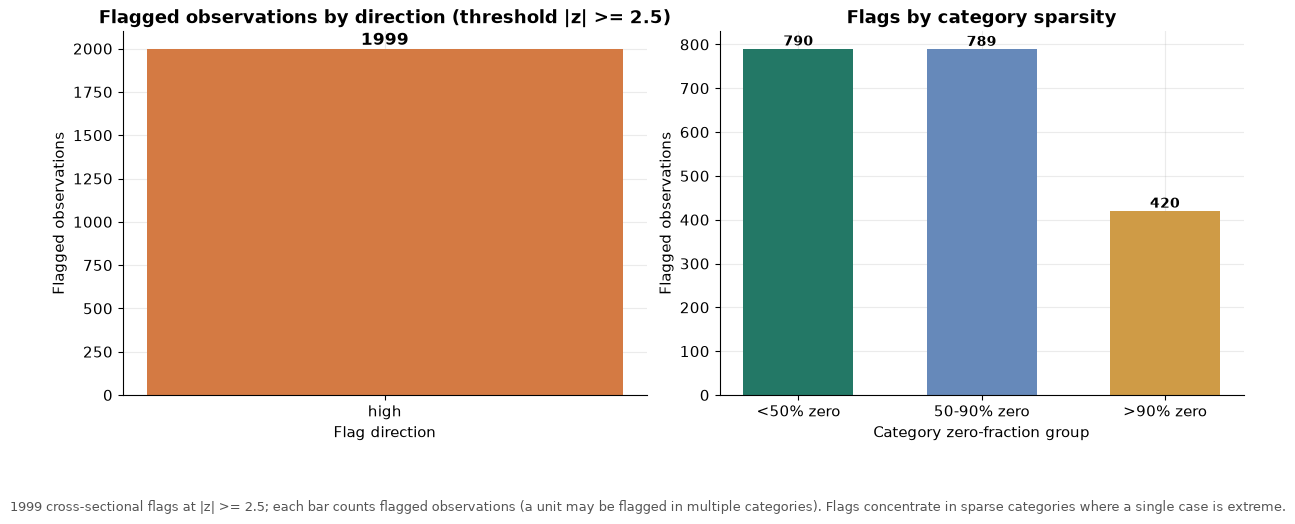

In [3]:

# Figure N04-01 · anomaly_flag_counts
# Flagged observations by anomaly group/direction using the active saved definitions (threshold |z|>=2.5).
from collections import Counter
flags = saved_anomalies["cross_sectional"]
direction_counts = Counter(f["direction"] for f in flags)
# group by category sparsity (zero fraction) for a meaningful breakdown
feat_df = pd.DataFrame(feature_rows)
feat24 = feat_df[(feat_df["year"] == 2024)]
zf_cat = feat24.groupby("category")["total"].apply(lambda s: (s == 0).mean())
flag_df = pd.DataFrame(flags)
flag_df["zero_fraction"] = flag_df["category"].map(zf_cat)
flag_df["sparsity_group"] = pd.cut(flag_df["zero_fraction"], bins=[0, 0.5, 0.9, 1.0],
                                   labels=["<50% zero", "50-90% zero", ">90% zero"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
axes[0].bar([str(k) for k in direction_counts.keys()], list(direction_counts.values()), color=[ACCENT, PRIMARY], width=0.5)
for i, (k, v) in enumerate(direction_counts.items()):
    axes[0].text(i, v, str(v), ha="center", va="bottom", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Flag direction"); axes[0].set_ylabel("Flagged observations")
axes[0].set_title(f"Flagged observations by direction (threshold |z| >= {threshold})")
sg = flag_df["sparsity_group"].value_counts().reindex(["<50% zero", "50-90% zero", ">90% zero"])
axes[1].bar([str(i) for i in sg.index], sg.values, color=SERIES[:len(sg)], width=0.6)
for i, v in enumerate(sg.values):
    axes[1].text(i, v, str(int(v)), ha="center", va="bottom", fontsize=10, fontweight="bold")
axes[1].set_xlabel("Category zero-fraction group"); axes[1].set_ylabel("Flagged observations")
axes[1].set_title("Flags by category sparsity")
fig_note(fig, f"{len(flags)} cross-sectional flags at |z| >= {threshold}; each bar counts flagged observations "
              "(a unit may be flagged in multiple categories). Flags concentrate in sparse categories where a single case is extreme.")
plt.show()


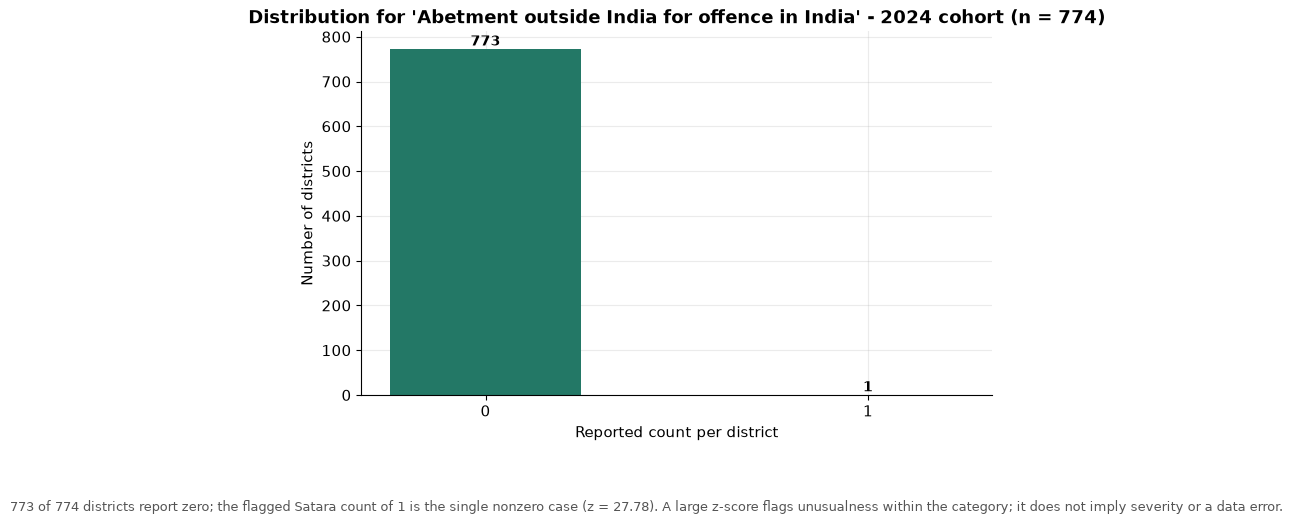

In [4]:

# Figure N04-02 · rare_category_anomaly_distribution
# Full observed frequency distribution for the Satara / Abetment outside India example.
rare_cat = rare["category"]
rare_vals = np.array([r["total"] for r in feature_rows if r["year"] == 2024 and r["category"] == rare_cat])
fig, ax = plt.subplots(figsize=(7, 4.4), constrained_layout=True)
uniq, counts = np.unique(rare_vals, return_counts=True)
ax.bar([str(int(u)) for u in uniq], counts, color=PRIMARY, width=0.5)
for x, c in zip(uniq, counts):
    ax.text(str(int(x)), c, str(int(c)), ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_xlabel("Reported count per district"); ax.set_ylabel("Number of districts")
ax.set_title(f"Distribution for '{rare_cat}' - 2024 cohort (n = {len(rare_vals)})")
fig_note(fig, f"{int((rare_vals==0).sum())} of {len(rare_vals)} districts report zero; the flagged Satara count of "
              f"{int(rare['value'])} is the single nonzero case (z = {rare['z_score']:.2f}). "
              "A large z-score flags unusualness within the category; it does not imply severity or a data error.")
plt.show()


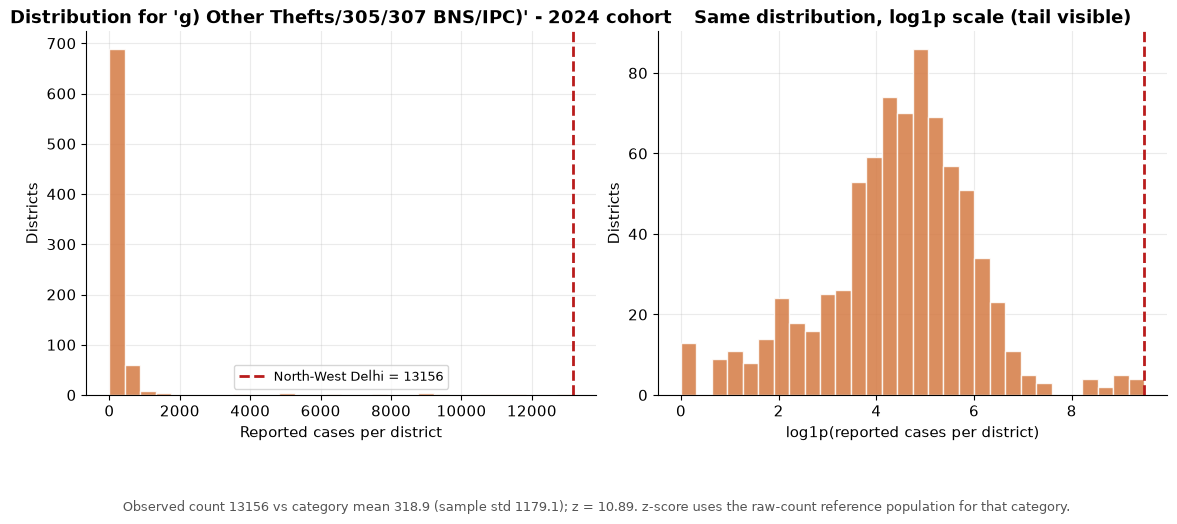

In [5]:

# Figure N04-03 · high_volume_anomaly_distribution
# Category distribution for North-West Delhi / Other Thefts example.
hv_cat = high_volume["category"]
hv_vals = np.array([r["total"] for r in feature_rows if r["year"] == 2024 and r["category"] == hv_cat])
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), constrained_layout=True)
axes[0].hist(hv_vals, bins=30, color=ACCENT, alpha=0.85, edgecolor="white")
axes[0].axvline(high_volume["value"], color=RED, ls="--", lw=2,
                label=f"North-West Delhi = {int(high_volume['value'])}")
axes[0].set_xlabel("Reported cases per district"); axes[0].set_ylabel("Districts")
axes[0].set_title(f"Distribution for '{hv_cat}' - 2024 cohort"); axes[0].legend(fontsize=9)
# tail panel: log1p
axes[1].hist(np.log1p(hv_vals), bins=30, color=ACCENT, alpha=0.85, edgecolor="white")
axes[1].axvline(np.log1p(high_volume["value"]), color=RED, ls="--", lw=2)
axes[1].set_xlabel("log1p(reported cases per district)"); axes[1].set_ylabel("Districts")
axes[1].set_title("Same distribution, log1p scale (tail visible)")
fig_note(fig, f"Observed count {int(high_volume['value'])} vs category mean {high_volume['category_mean']:.1f} "
              f"(sample std {high_volume['category_std']:.1f}); z = {high_volume['z_score']:.2f}. "
              "z-score uses the raw-count reference population for that category.")
plt.show()


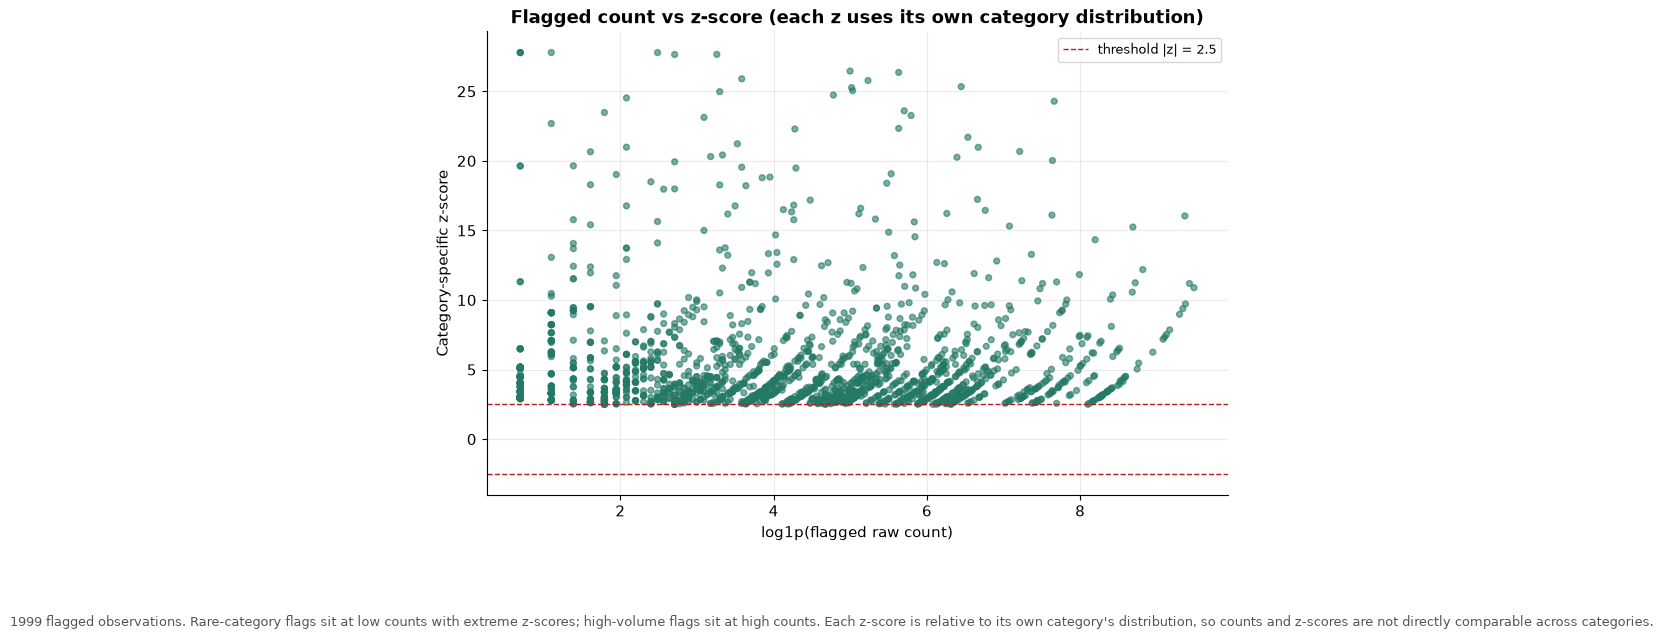

In [6]:

# Figure N04-04 · anomaly_count_vs_z_score
# Scatter of flagged raw counts vs category-specific z-scores; rare vs high-volume distinguished.
flag_df_plot = flag_df.copy()
flag_df_plot["log1p_value"] = np.log1p(flag_df_plot["value"].fillna(0))
fig, ax = plt.subplots(figsize=(8, 5.4), constrained_layout=True)
ax.scatter(flag_df_plot["log1p_value"], flag_df_plot["z_score"], s=18, alpha=0.6,
           c=np.where(flag_df_plot["direction"] == "high", PRIMARY, ACCENT))
ax.set_xlabel("log1p(flagged raw count)"); ax.set_ylabel("Category-specific z-score")
ax.set_title("Flagged count vs z-score (each z uses its own category distribution)")
ax.axhline(threshold, color=RED, ls="--", lw=1, label=f"threshold |z| = {threshold}")
ax.axhline(-threshold, color=RED, ls="--", lw=1)
ax.legend(fontsize=9)
fig_note(fig, f"{len(flag_df_plot)} flagged observations. Rare-category flags sit at low counts with extreme z-scores; "
              "high-volume flags sit at high counts. Each z-score is relative to its own category's distribution, "
              "so counts and z-scores are not directly comparable across categories.")
plt.show()


Satara’s single recorded case is extreme relative to a category that is zero in nearly every district, so its z-score is large even though the raw count is one. A z-score flags unusualness within a category; it does not imply severity or indicate a data error.

## Association rules from district profiles

The runner defines an item as a category with at least 10 reported cases in a district. Districts whose profile has no items at that cutoff do not form transactions. The saved Apriori settings also require support ≥0.15, confidence ≥0.60, maximum itemset size 2, and lift ≥1.05.

In [7]:
from crimescope_analysis.methods.association import load_feature_matrix as load_association_rows, build_transactions, apriori

association_relative = run["methods"]["association"]["artifact"]
association_path = artifact(association_relative)
saved_rules = json.loads(association_path.read_text(encoding="utf-8"))
params = run["parameters"]["association"]
association_rows = load_association_rows(feature_path)
transactions = build_transactions(association_rows, 2024, min_cases=params["min_cases"])
cohort_districts = len({r["region_id"] for r in association_rows})
excluded_empty_profiles = cohort_districts - len(transactions)
assert len(transactions) == saved_rules["n_transactions"] == run["methods"]["association"]["transactions"] == 739
assert excluded_empty_profiles == run["exclusions"]["association_districts_without_items_at_min_cases"] == 35

recomputed_rules = apriori(transactions, min_support=params["min_support"], min_confidence=params["min_confidence"],
                           max_itemset_size=params["max_itemset_size"], min_lift=params["min_lift"])
assert recomputed_rules["n_rules"] == saved_rules["n_rules"] == run["methods"]["association"]["rules"] == 697

rule = next(r for r in saved_rules["rules"] if r["antecedent"] == ["Stalking"] and r["consequent"] == ["Arson,326 & 327 BNS/Section 435,436 & 438 IPC)"])
antecedent, consequent = rule["antecedent"][0], rule["consequent"][0]
n = len(transactions)
n_antecedent = sum(antecedent in t for t in transactions)
n_consequent = sum(consequent in t for t in transactions)
n_joint = sum(antecedent in t and consequent in t for t in transactions)
support = n_joint / n
confidence = n_joint / n_antecedent
consequent_prevalence = n_consequent / n
lift = confidence / consequent_prevalence
rule_metrics = pd.DataFrame([{
    "saved rule": f"{antecedent} -> {consequent}", "transactions N": n,
    "antecedent count": n_antecedent, "consequent count": n_consequent, "joint count": n_joint,
    "support = joint / N": support, "confidence = joint / antecedent": confidence,
    "consequent prevalence": consequent_prevalence, "lift = confidence / prevalence": lift,
}])
display(rule_metrics.round(4))
assert (n_antecedent, n_consequent, n_joint) == (184, 218, 123)
assert np.isclose(support, rule["support"], atol=.0001)
assert np.isclose(confidence, rule["confidence"], atol=.0001)
assert np.isclose(lift, rule["lift"], atol=.0001)

,saved rule,transactions N,antecedent count,consequent count,joint count,support = joint / N,confidence = joint / antecedent,consequent prevalence,lift = confidence / prevalence
0,"Stalking -> Arson,326 & 327 BNS/Section 435,43...",739,184,218,123,0.1664,0.6685,0.295,2.2661


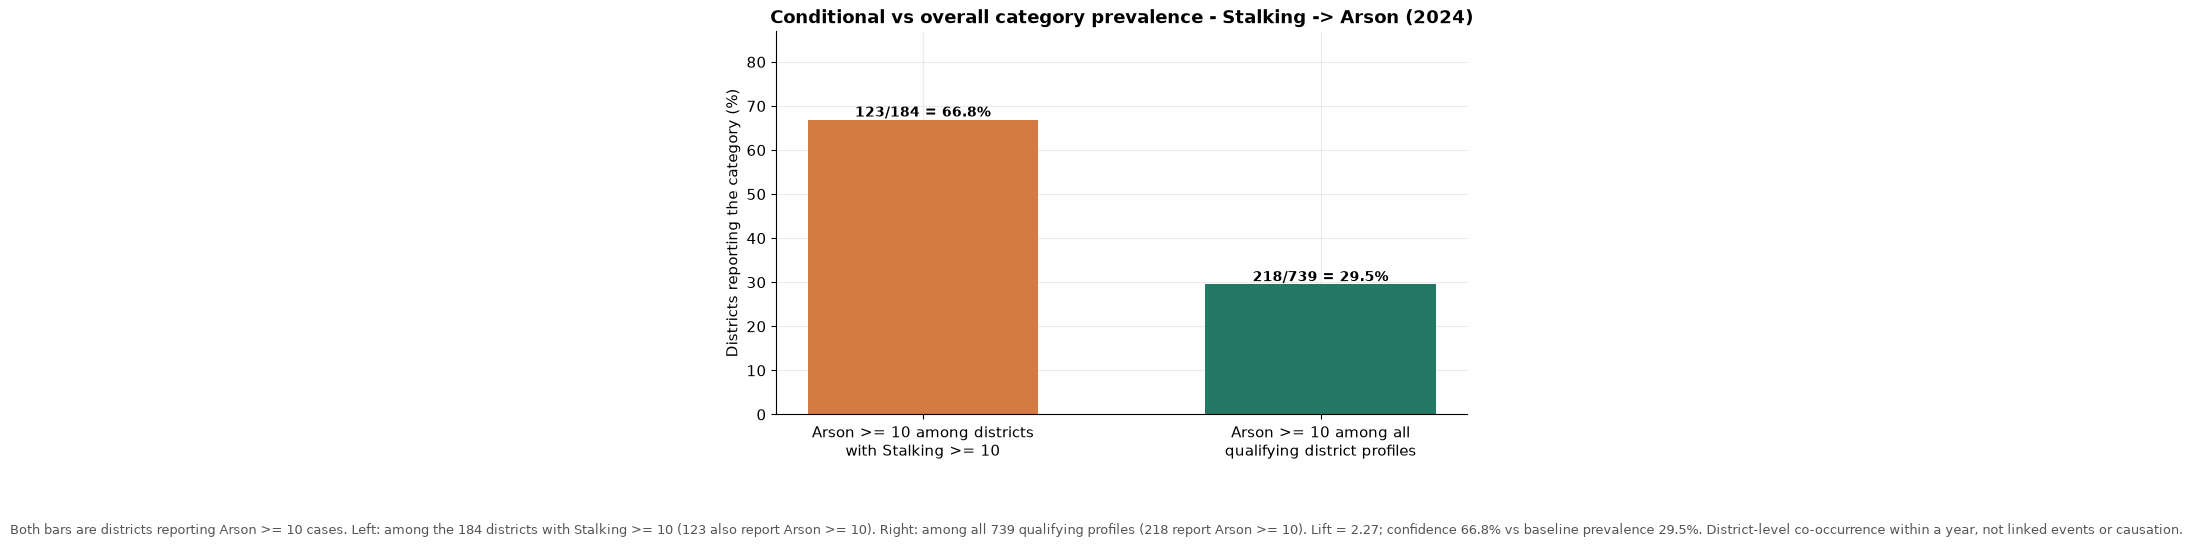

In [8]:

# Figure N04-06 · arson_prevalence_given_stalking_2024 (improved)
# Conditional vs overall Arson prevalence, both bars labelled Arson >= 10 reported cases.
fig, ax = plt.subplots(figsize=(7.5, 4.6), constrained_layout=True)
labels = ["Arson >= 10 among districts\nwith Stalking >= 10", "Arson >= 10 among all\nqualifying district profiles"]
values = [confidence * 100, consequent_prevalence * 100]
bars = ax.bar(labels, values, color=[ACCENT, PRIMARY], width=0.58)
ax.set_ylabel("Districts reporting the category (%)")
ax.set_title("Conditional vs overall category prevalence - Stalking -> Arson (2024)")
ax.set_ylim(0, max(values) * 1.30)
for bar, count, denom, value in zip(bars, [n_joint, n_consequent], [n_antecedent, n], values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f"{count}/{denom} = {value:.1f}%", ha="center", va="bottom", fontsize=10, fontweight="bold")
fig_note(fig, f"Both bars are districts reporting Arson >= 10 cases. Left: among the {n_antecedent} districts with Stalking >= 10 "
              f"({n_joint} also report Arson >= 10). Right: among all {n} qualifying profiles ({n_consequent} report Arson >= 10). "
              f"Lift = {lift:.2f}; confidence {confidence*100:.1f}% vs baseline prevalence {consequent_prevalence*100:.1f}%. "
              "District-level co-occurrence within a year, not linked events or causation.")
plt.show()


## Association-rule coverage and the worked rule

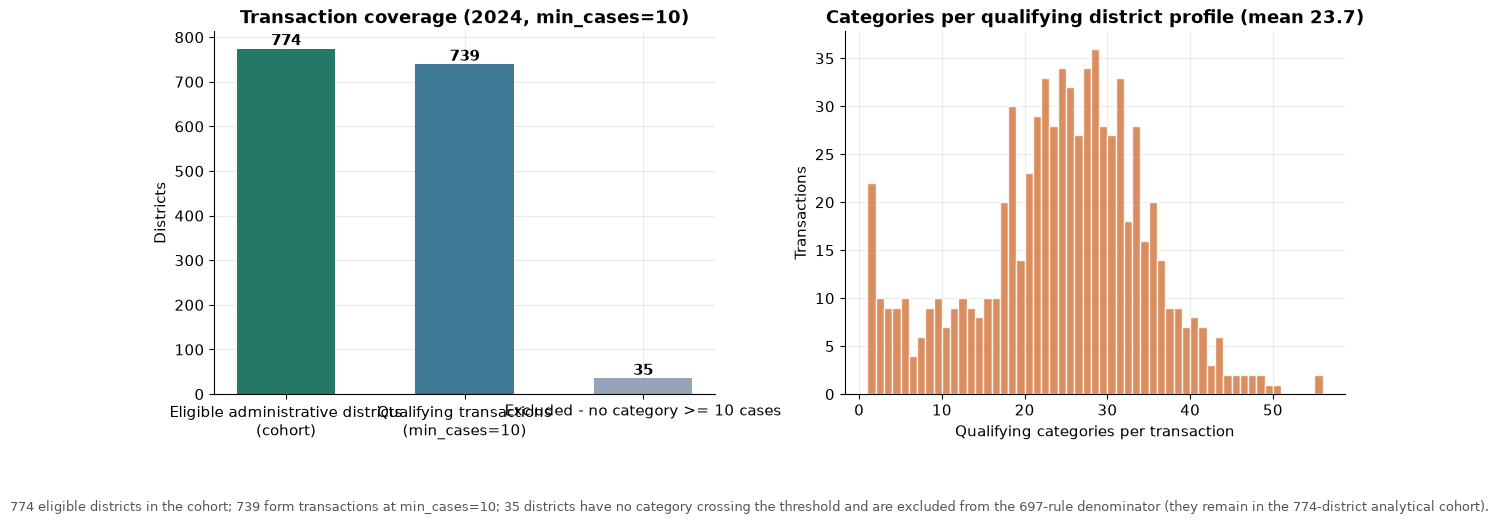

In [9]:

# Figure N04-05 · association_transaction_coverage
# Eligible cohort, qualifying transaction population, excluded empty profiles; categories-per-transaction histogram.
n_transactions = len(transactions)
cats_per_txn = [len(t) for t in transactions]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
n_rules = saved_rules["n_rules"]
axes[0].bar(["Eligible administrative districts\n(cohort)", "Qualifying transactions\n(min_cases=10)",
            "Excluded - no category >= 10 cases"],
            [cohort_districts, n_transactions, excluded_empty_profiles],
            color=[PRIMARY, BLUE, GREY], width=0.55)
for i, v in enumerate([cohort_districts, n_transactions, excluded_empty_profiles]):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Districts"); axes[0].set_title("Transaction coverage (2024, min_cases=10)")
axes[1].hist(cats_per_txn, bins=range(1, max(cats_per_txn) + 2), color=ACCENT, alpha=0.85, edgecolor="white")
axes[1].set_xlabel("Qualifying categories per transaction"); axes[1].set_ylabel("Transactions")
axes[1].set_title(f"Categories per qualifying district profile (mean {np.mean(cats_per_txn):.1f})")
fig_note(fig, f"{cohort_districts} eligible districts in the cohort; {n_transactions} form transactions at min_cases={params['min_cases']}; "
              f"{excluded_empty_profiles} districts have no category crossing the threshold and are excluded from the "
              f"{n_rules}-rule denominator (they remain in the 774-district analytical cohort).")
plt.show()


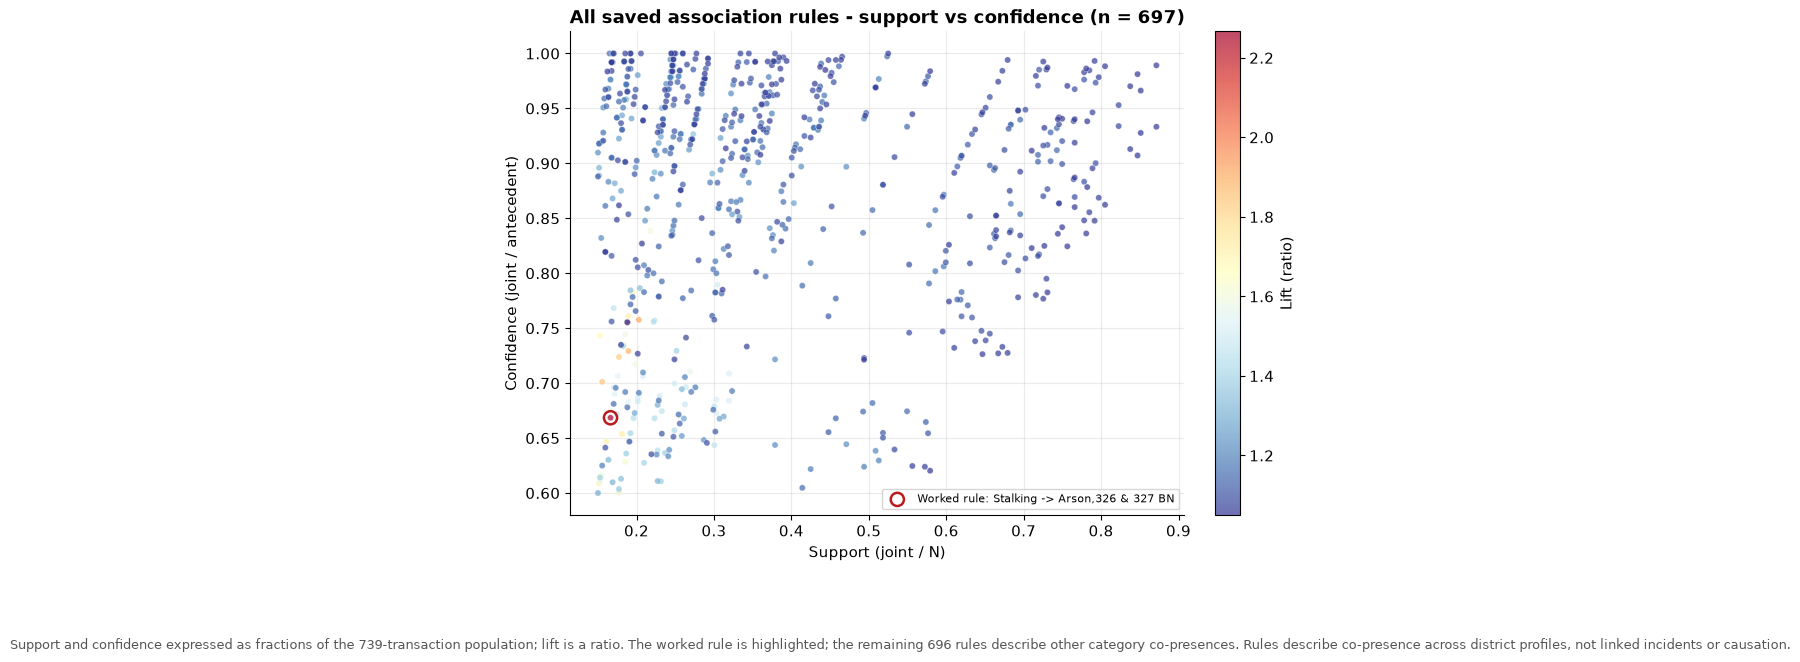

In [10]:

# Figure N04-07 · association_rule_metrics
# Support vs confidence for all saved rules, lift encoded by colour; worked rule highlighted.
rules_df = pd.DataFrame(saved_rules["rules"])
worked = (rules_df["antecedent"].apply(lambda a: a[0] if isinstance(a, list) else a) == antecedent) & \
         (rules_df["consequent"].apply(lambda c: c[0] if isinstance(c, list) else c) == consequent)

fig, ax = plt.subplots(figsize=(8, 5.6), constrained_layout=True)
sc = ax.scatter(rules_df["support"], rules_df["confidence"], c=rules_df["lift"], cmap="RdYlBu_r",
                s=20, alpha=0.7, edgecolor="white", linewidth=0.3)
ax.scatter(rules_df.loc[worked, "support"], rules_df.loc[worked, "confidence"], s=90, facecolors="none",
           edgecolors=RED, linewidths=1.8, label=f"Worked rule: {antecedent[:18]} -> {consequent[:18]}")
ax.set_xlabel("Support (joint / N)"); ax.set_ylabel("Confidence (joint / antecedent)")
ax.set_title(f"All saved association rules - support vs confidence (n = {saved_rules['n_rules']})")
ax.legend(fontsize=8)
fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04).set_label("Lift (ratio)")
fig_note(fig, f"Support and confidence expressed as fractions of the {n}-transaction population; lift is a ratio. "
              "The worked rule is highlighted; the remaining 696 rules describe other category co-presences. "
              "Rules describe co-presence across district profiles, not linked incidents or causation.")
plt.show()


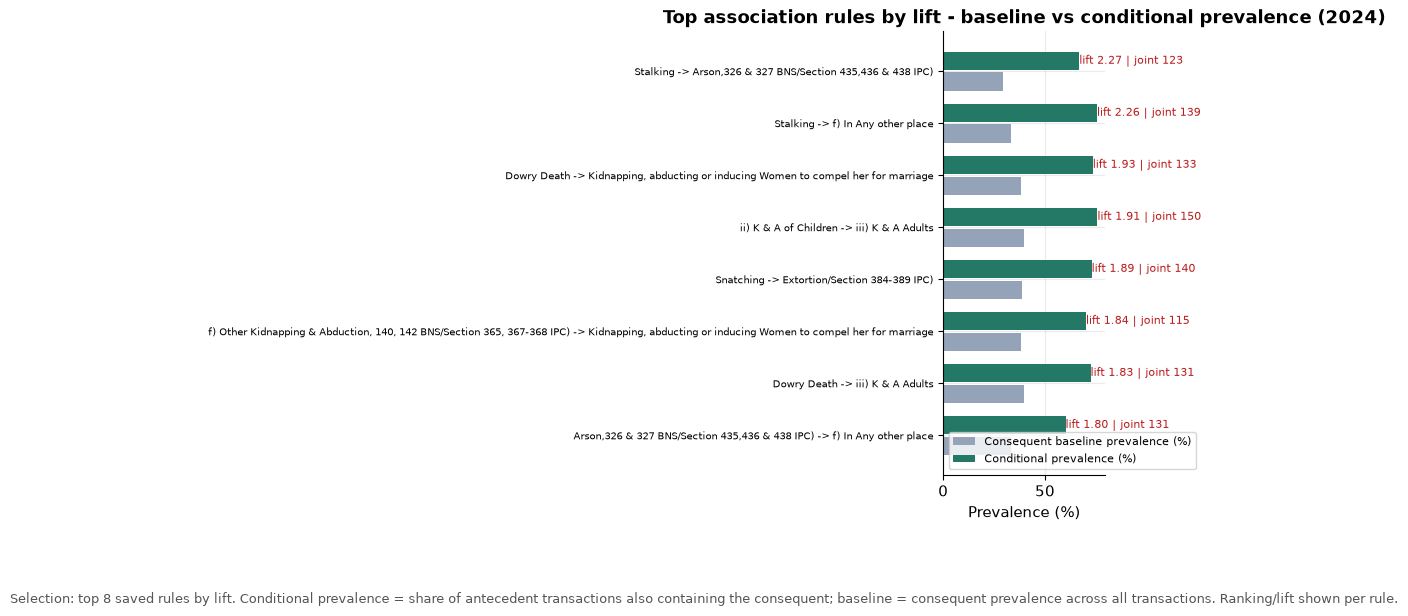

In [11]:

# Figure N04-08 · selected_association_rules
# Top rules by lift: consequent baseline prevalence vs conditional prevalence, with support/joint count and lift.
top_rules = rules_df.sort_values("lift", ascending=False).head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.2), constrained_layout=True)
y = np.arange(len(top_rules))
cond = [r["confidence"] * 100 for _, r in top_rules.iterrows()]
base = []
for _, r in top_rules.iterrows():
    cons = r["consequent"][0] if isinstance(r["consequent"], list) else r["consequent"]
    # baseline prevalence: share of qualifying transactions containing the consequent item (count >= 10)
    ncons = sum(1 for tr in transactions if cons in tr)
    base.append(100 * ncons / n)
ax.barh(y - 0.2, base, height=0.35, label="Consequent baseline prevalence (%)", color=GREY)
ax.barh(y + 0.2, cond, height=0.35, label="Conditional prevalence (%)", color=PRIMARY)
for i, (_, r) in enumerate(top_rules.iterrows()):
    ant = r["antecedent"][0] if isinstance(r["antecedent"], list) else r["antecedent"]
    con = r["consequent"][0] if isinstance(r["consequent"], list) else r["consequent"]
    ax.text(cond[i], i + 0.2, f"lift {r['lift']:.2f} | joint {int(r['support_count'])}", va="center", ha="left", fontsize=8, color=RED)
ax.set_yticks(y)
ax.set_yticklabels([f"{r['antecedent'][0] if isinstance(r['antecedent'],list) else r['antecedent'][:20]} -> {r['consequent'][0] if isinstance(r['consequent'],list) else r['consequent'][:20]}" for _, r in top_rules.iterrows()], fontsize=7)
ax.set_xlabel("Prevalence (%)")
ax.set_title("Top association rules by lift - baseline vs conditional prevalence (2024)")
ax.legend(fontsize=8)
fig_note(fig, "Selection: top 8 saved rules by lift. Conditional prevalence = share of antecedent transactions also "
              "containing the consequent; baseline = consequent prevalence across all transactions. Ranking/lift shown per rule.")
plt.show()


### Interpretation and limitations

Support is the share of transactions containing both items; confidence is the share of Stalking-item transactions that also contain the Arson item; lift compares that conditional prevalence with Arson’s overall prevalence. The unit of analysis is one district’s 2024 reporting profile, and each item means the district reported at least 10 cases in that category.

These measures describe category co-presence across district profiles. They do not show that events occurred together, that one category caused another, or that a district is unsafe. The 35 empty profiles are excluded from the 739-transaction rule denominator, but remain part of the original 774-district analytical cohort.

## Appendix: additional anomaly and rule diagnostics

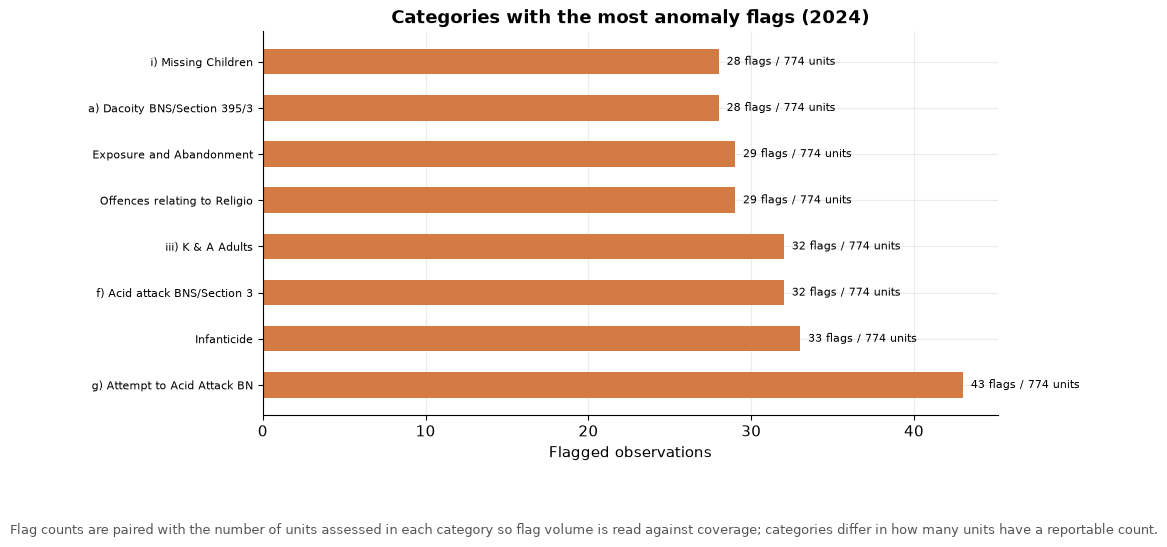

In [12]:

# Figure N04-09 · anomalies_by_category_and_volume (optional)
# Small set of categories with the most flags, flag counts paired with units assessed.
cat_flags = flag_df.groupby("category").size().sort_values(ascending=False).head(8)
feat24n = pd.DataFrame([r for r in feature_rows if r["year"] == 2024])
cat_units = feat24n.groupby("category")["region_id"].nunique()
fig, ax = plt.subplots(figsize=(10, 4.6), constrained_layout=True)
y = np.arange(len(cat_flags))
ax.barh(y, cat_flags.values, color=ACCENT, height=0.55)
for i, v in enumerate(cat_flags.values):
    ax.text(v, i, f"  {int(v)} flags / {int(cat_units[cat_flags.index[i]])} units", va="center", fontsize=8)
ax.set_yticks(y)
ax.set_yticklabels([c[:28] for c in cat_flags.index], fontsize=8)
ax.set_xlabel("Flagged observations"); ax.set_title("Categories with the most anomaly flags (2024)")
fig_note(fig, "Flag counts are paired with the number of units assessed in each category so flag volume is read "
              "against coverage; categories differ in how many units have a reportable count.")
plt.show()


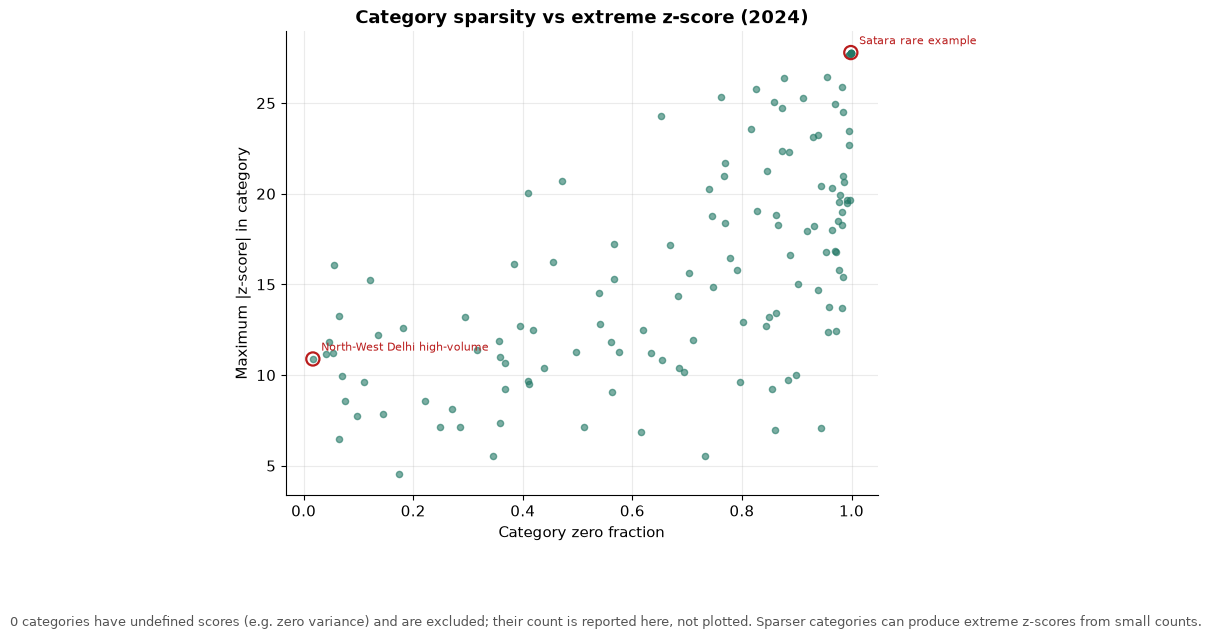

In [13]:

# Figure N04-10 · rare_category_sparsity_vs_extreme_z (optional)
# Category zero fraction vs maximum |z| across categories with a valid reference distribution.
cat_z = flag_df.groupby("category")["z_score"].apply(lambda s: s.abs().max())
cat_zf = zf_cat.reindex(cat_z.index)
valid = cat_z.notna() & cat_zf.notna()
fig, ax = plt.subplots(figsize=(7.5, 5.4), constrained_layout=True)
ax.scatter(cat_zf[valid], cat_z[valid], s=20, alpha=0.6, color=PRIMARY)
# highlight worked examples
for name, label in [(rare_cat, "Satara rare example"), (hv_cat, "North-West Delhi high-volume")]:
    if name in cat_zf.index and valid[name]:
        ax.scatter(cat_zf[name], cat_z[name], s=90, facecolors="none", edgecolors=RED, linewidths=1.6)
        ax.annotate(label, (cat_zf[name], cat_z[name]), textcoords="offset points", xytext=(6, 6), fontsize=8, color=RED)
ax.set_xlabel("Category zero fraction"); ax.set_ylabel("Maximum |z-score| in category")
ax.set_title("Category sparsity vs extreme z-score (2024)")
fig_note(fig, f"{int((~valid).sum())} categories have undefined scores (e.g. zero variance) and are excluded; their count is reported here, not plotted. "
              "Sparser categories can produce extreme z-scores from small counts.")
plt.show()


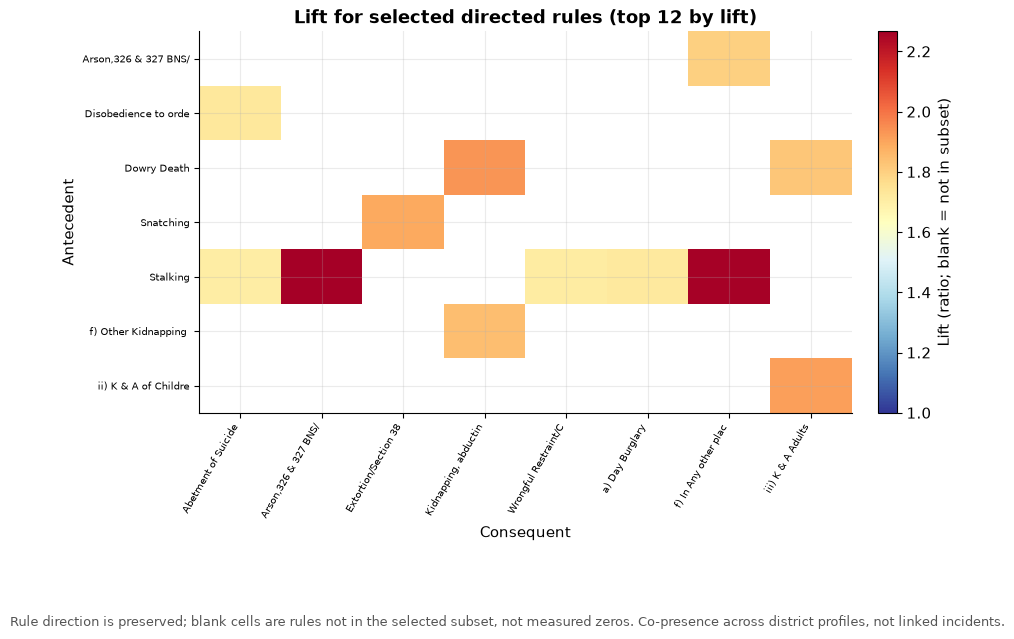

In [14]:

# Figure N04-11 · association_antecedent_consequent_heatmap (optional)
# Lift for a manageable subset of directed rules.
subset = rules_df.sort_values("lift", ascending=False).head(12)
ants = sorted(set(a[0] for a in subset["antecedent"]))
cons = sorted(set(c[0] for c in subset["consequent"]))
lift_mat = np.full((len(ants), len(cons)), np.nan)
for _, r in subset.iterrows():
    a = r["antecedent"][0] if isinstance(r["antecedent"], list) else r["antecedent"]
    c = r["consequent"][0] if isinstance(r["consequent"], list) else r["consequent"]
    if a in ants and c in cons:
        lift_mat[ants.index(a), cons.index(c)] = r["lift"]
fig, ax = plt.subplots(figsize=(9, 5.4), constrained_layout=True)
im = ax.imshow(lift_mat, aspect="auto", cmap="RdYlBu_r", vmin=1, vmax=np.nanmax(lift_mat))
ax.set_xticks(range(len(cons))); ax.set_xticklabels([c[:20] for c in cons], rotation=60, ha="right", fontsize=7)
ax.set_yticks(range(len(ants))); ax.set_yticklabels([a[:20] for a in ants], fontsize=7)
ax.set_xlabel("Consequent"); ax.set_ylabel("Antecedent")
ax.set_title("Lift for selected directed rules (top 12 by lift)")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).set_label("Lift (ratio; blank = not in subset)")
fig_note(fig, "Rule direction is preserved; blank cells are rules not in the selected subset, not measured zeros. "
              "Co-presence across district profiles, not linked incidents.")
plt.show()


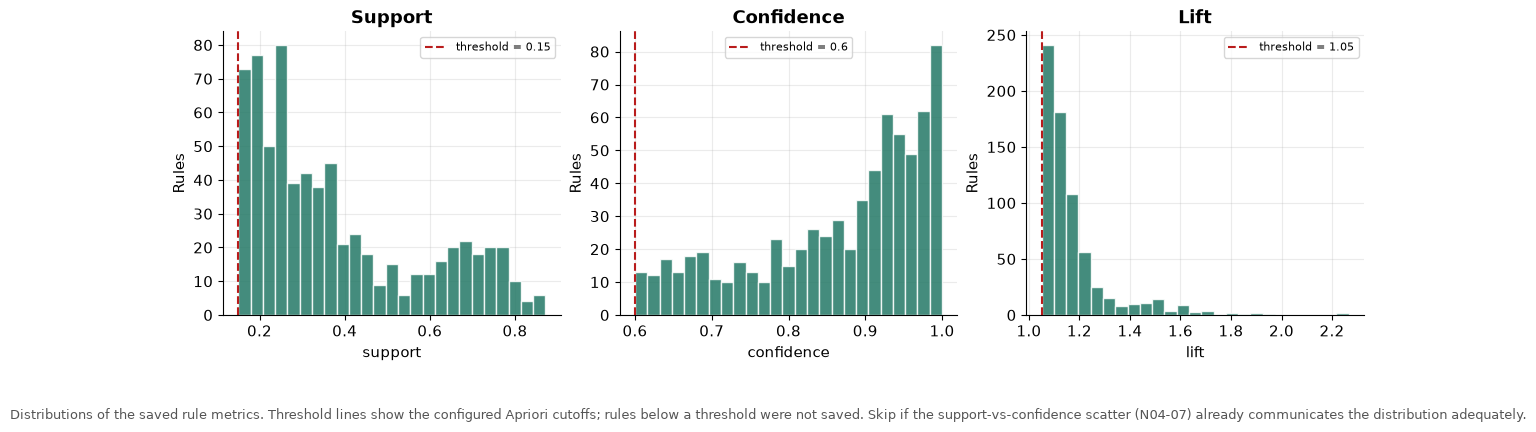

In [15]:

# Figure N04-12 · association_support_confidence_lift_distributions (optional)
# Compact histograms of saved rule metrics with threshold lines.
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), constrained_layout=True)
for ax, col, thr, ttl in [(axes[0], "support", params["min_support"], "Support"),
                          (axes[1], "confidence", params["min_confidence"], "Confidence"),
                          (axes[2], "lift", params["min_lift"], "Lift")]:
    ax.hist(rules_df[col], bins=25, color=PRIMARY, alpha=0.85, edgecolor="white")
    ax.axvline(thr, color=RED, ls="--", lw=1.5, label=f"threshold = {thr}")
    ax.set_xlabel(col); ax.set_ylabel("Rules"); ax.set_title(ttl)
    ax.legend(fontsize=8)
fig_note(fig, "Distributions of the saved rule metrics. Threshold lines show the configured Apriori cutoffs; "
              "rules below a threshold were not saved. Skip if the support-vs-confidence scatter (N04-07) already "
              "communicates the distribution adequately.")
plt.show()
